# European Union inflation replication: 2007–2025

In [ ]:
from pathlib import Path
import json
import sys
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'modelling').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from modelling.europe_figures import (
    plot_state_lag_selection, plot_european_regimes, plot_evaluation_timeline,
)

DATASET = ROOT / 'data/processed/europe/eu27_guardian_monthly_experiment.csv'
RESULTS = ROOT / 'data/processed/europe/eu27_guardian_results_2022_2025.json'
data = pd.read_csv(DATASET, parse_dates=['Date'])
results = json.loads(RESULTS.read_text(encoding='utf-8'))
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

# Git-tracked exports shared with Chapter 4 of the thesis.
FIGURE_DIR = ROOT / 'modelling/notebooks/figures/chapter4'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure_provenance = {
    'results_file': RESULTS.relative_to(ROOT).as_posix(),
    'results_sha256': hashlib.sha256(RESULTS.read_bytes()).hexdigest(),
    'notebook': 'modelling/notebooks/03_European_Union_Replication.ipynb',
    'plotting_module': 'modelling/europe_figures.py',
    'figures': {},
}

def export_chapter4_figure(fig, filename, details):
    fig.savefig(FIGURE_DIR / filename, dpi=300, facecolor='white', bbox_inches='tight')
    figure_provenance['figures'][filename] = details
    (FIGURE_DIR / 'provenance.json').write_text(
        json.dumps(figure_provenance, ensure_ascii=False, indent=2) + '\n',
        encoding='utf-8',
    )


## Chapter 4: estimation and evaluation timeline


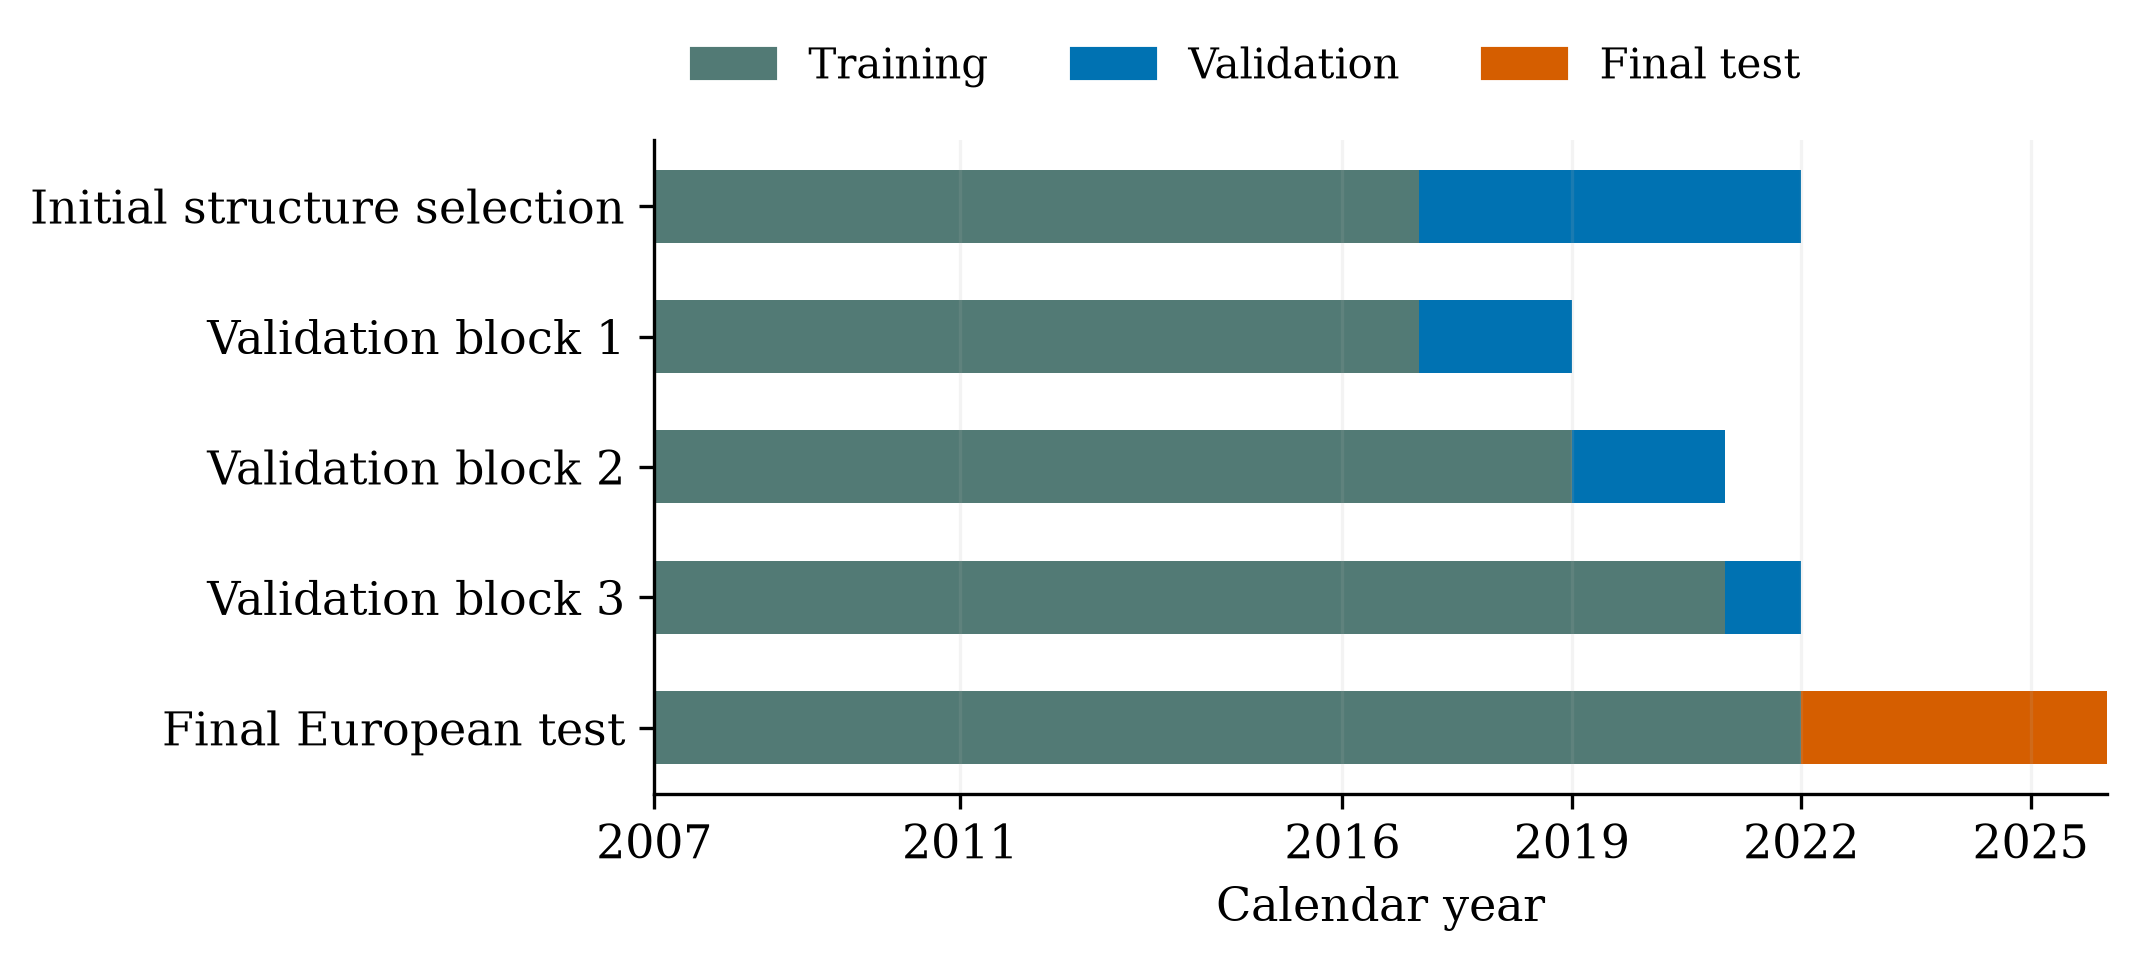

In [ ]:
timeline_figure = plot_evaluation_timeline(results)
export_chapter4_figure(timeline_figure, 'evaluation_timeline.png', {
    'thesis_figure': '4.3',
    'source': ['structure_validation.design', 'macro_experiment.rolling_validation.folds'],
    'selection_design': results['structure_validation']['design'],
    'validation_blocks': [fold['fold'] for fold in results['macro_experiment']['rolling_validation']['folds']],
})
display(timeline_figure)
plt.close(timeline_figure)


## Data coverage

,EU-27 replication
First month,2007-01-01
Last month,2025-12-01
Months,228
Guardian articles,29080
Scored test months,48


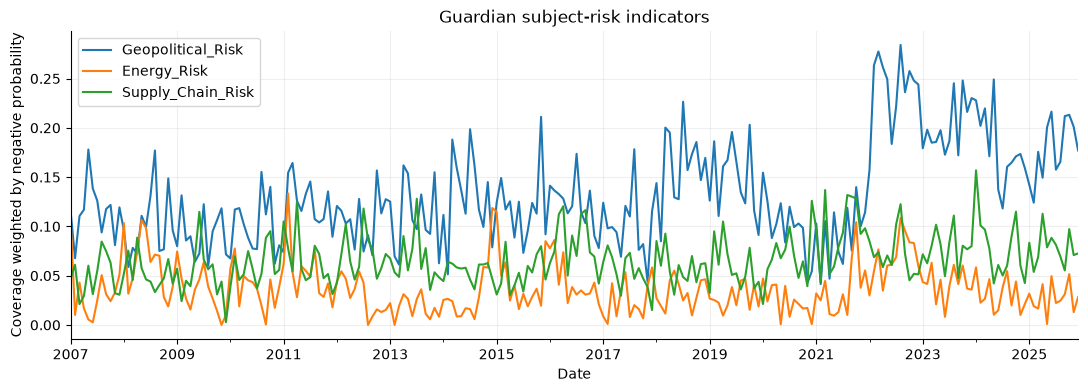

In [2]:
display(pd.Series({
    'First month': data.Date.min().date(),
    'Last month': data.Date.max().date(),
    'Months': len(data),
    'Guardian articles': int(data.Article_Count.sum()),
    'Scored test months': len(results['models'][0]['forecasts']),
}, name='EU-27 replication').to_frame())
data.set_index('Date')[['Geopolitical_Risk', 'Energy_Risk', 'Supply_Chain_Risk']].plot(
    figsize=(13, 4), title='Guardian subject-risk indicators')
plt.ylabel('Coverage weighted by negative probability')
plt.grid(alpha=.2)
plt.show()

## Out-of-sample forecast results

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,AR-HMM(1) + all subject risks,AR-HMM,0.4522,0.3204,0.1496
1,AR-HMM(1) + supply-chain risk,AR-HMM,0.4547,0.3075,0.1434
2,AR-HMM(1) + lagged sentiment,AR-HMM,0.4614,0.3198,0.1755
3,AR-HMM(1) + energy risk,AR-HMM,0.4633,0.3255,0.1672
4,AR-HMM(1),AR-HMM,0.4658,0.3203,0.1791
5,MS-Variance AR(1) + energy risk,MS-Variance,0.4663,0.3287,0.1147
6,AR-HMM(1) + geopolitical risk,AR-HMM,0.4666,0.3309,0.1806
7,AR-HMM(1) + sentiment dispersion,AR-HMM,0.4696,0.3237,0.1890
8,AR(1) + all subject risks,AR,0.4760,0.3232,0.1512
9,MS-Variance AR(1) + supply-chain risk,MS-Variance,0.4782,0.3259,0.1181


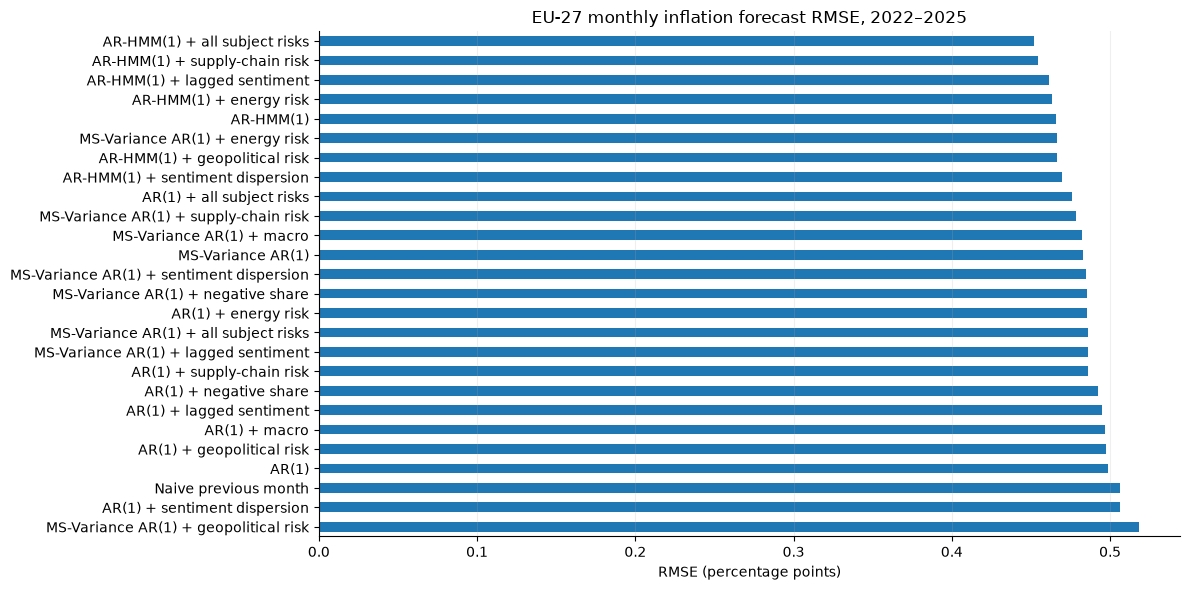

In [3]:
table = pd.DataFrame([{'model': item['model'], 'family': item['family'], **item['metrics']}
                      for item in results['models']]).sort_values('rmse').reset_index(drop=True)
display(table.round(4))
ordered = table.sort_values('rmse', ascending=False)
ordered.plot.barh(x='model', y='rmse', legend=False, figsize=(12, 6),
                  title='EU-27 monthly inflation forecast RMSE, 2022–2025')
plt.xlabel('RMSE (percentage points)')
plt.ylabel('')
plt.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

## Winner robustness

In [4]:
diagnostics = results['diagnostics']
seed_runs = pd.DataFrame(diagnostics['winner_initialization_robustness'])
display(pd.Series({
    'Winner': diagnostics['winner'],
    'RMSE range across five seeds': f"{seed_runs.rmse.min():.4f}–{seed_runs.rmse.max():.4f}",
    'Loss-test p-value versus AR(1)': diagnostics['newey_west_lag1_loss_test_pvalues']['AR(1)'],
    'Loss-test p-value versus AR-HMM(1)': diagnostics['newey_west_lag1_loss_test_pvalues']['AR-HMM(1)'],
}, name='Robustness').to_frame())

,Robustness
Winner,AR-HMM(1) + all subject risks
RMSE range across five seeds,0.4522–0.4523
Loss-test p-value versus AR(1),0.058468
Loss-test p-value versus AR-HMM(1),0.33431


## Best model versus AR benchmark

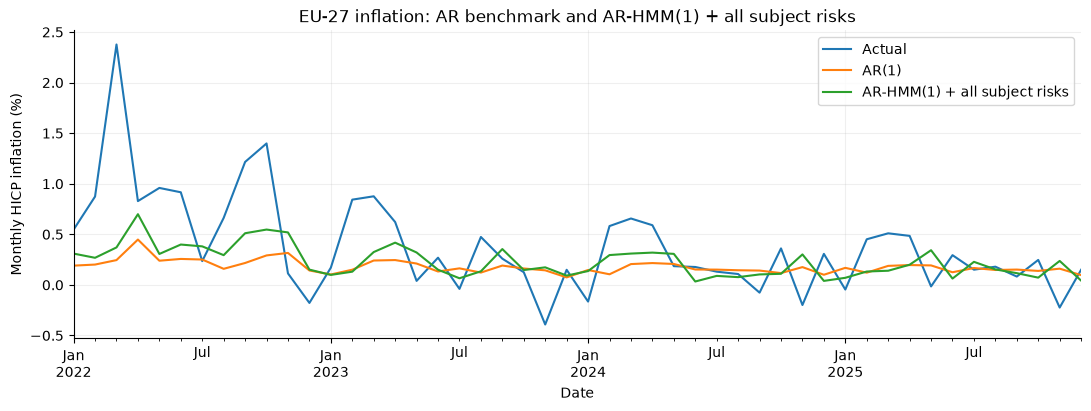

In [5]:
best_name = table.iloc[0].model
selected = [item for item in results['models'] if item['model'] in {'AR(1)', best_name}]
plot = None
for item in selected:
    frame = pd.DataFrame(item['forecasts'])
    frame['Date'] = pd.to_datetime(frame.Date)
    if plot is None:
        plot = frame[['Date', 'Actual']].set_index('Date')
    plot[item['model']] = frame.set_index('Date').Forecast
plot.plot(figsize=(13, 4), title=f'EU-27 inflation: AR benchmark and {best_name}')
plt.ylabel('Monthly HICP inflation (%)')
plt.grid(alpha=.2)
plt.show()

## Lag and hidden-state validation

In [6]:
selection = results['structure_validation']
validation = pd.DataFrame([{'model': item['model'], **item['metrics'], 'converged': item['converged']}
                           for item in selection['validation_candidates']]).sort_values('rmse')
display(validation.round(4))
display(pd.DataFrame([{'model': item['model'], **item['metrics']}
                      for item in selection['final_test']]).round(4))

,model,rmse,mae,mean_error_actual_minus_forecast,converged
1,"AR-HMM(1), 2 states",0.3775,0.2900,0.0283,True
5,"AR-HMM(2), 3 states",0.3813,0.2855,0.0358,True
2,"AR-HMM(1), 3 states",0.3844,0.2937,0.0725,True
9,"AR-HMM(1), 2 states, common AR",0.3862,0.2950,0.0283,True
0,AR(1),0.3895,0.2987,0.0256,True
4,"AR-HMM(2), 2 states",0.3898,0.3054,0.0664,True
10,"MS-Variance AR(1), 2 states",0.3932,0.2916,-0.0428,True
8,"AR-HMM(3), 3 states",0.3963,0.3034,0.0572,True
6,AR(3),0.3983,0.3029,0.0371,True
3,AR(2),0.3997,0.3030,0.0322,True


,model,rmse,mae,mean_error_actual_minus_forecast
0,"Selected AR-HMM(1), 2 states baseline",0.4658,0.3203,0.1791
1,"Selected AR-HMM(1), 2 states + all subject risks",0.4522,0.3204,0.1496


### Chapter 4: selection of state count and inflation lag order


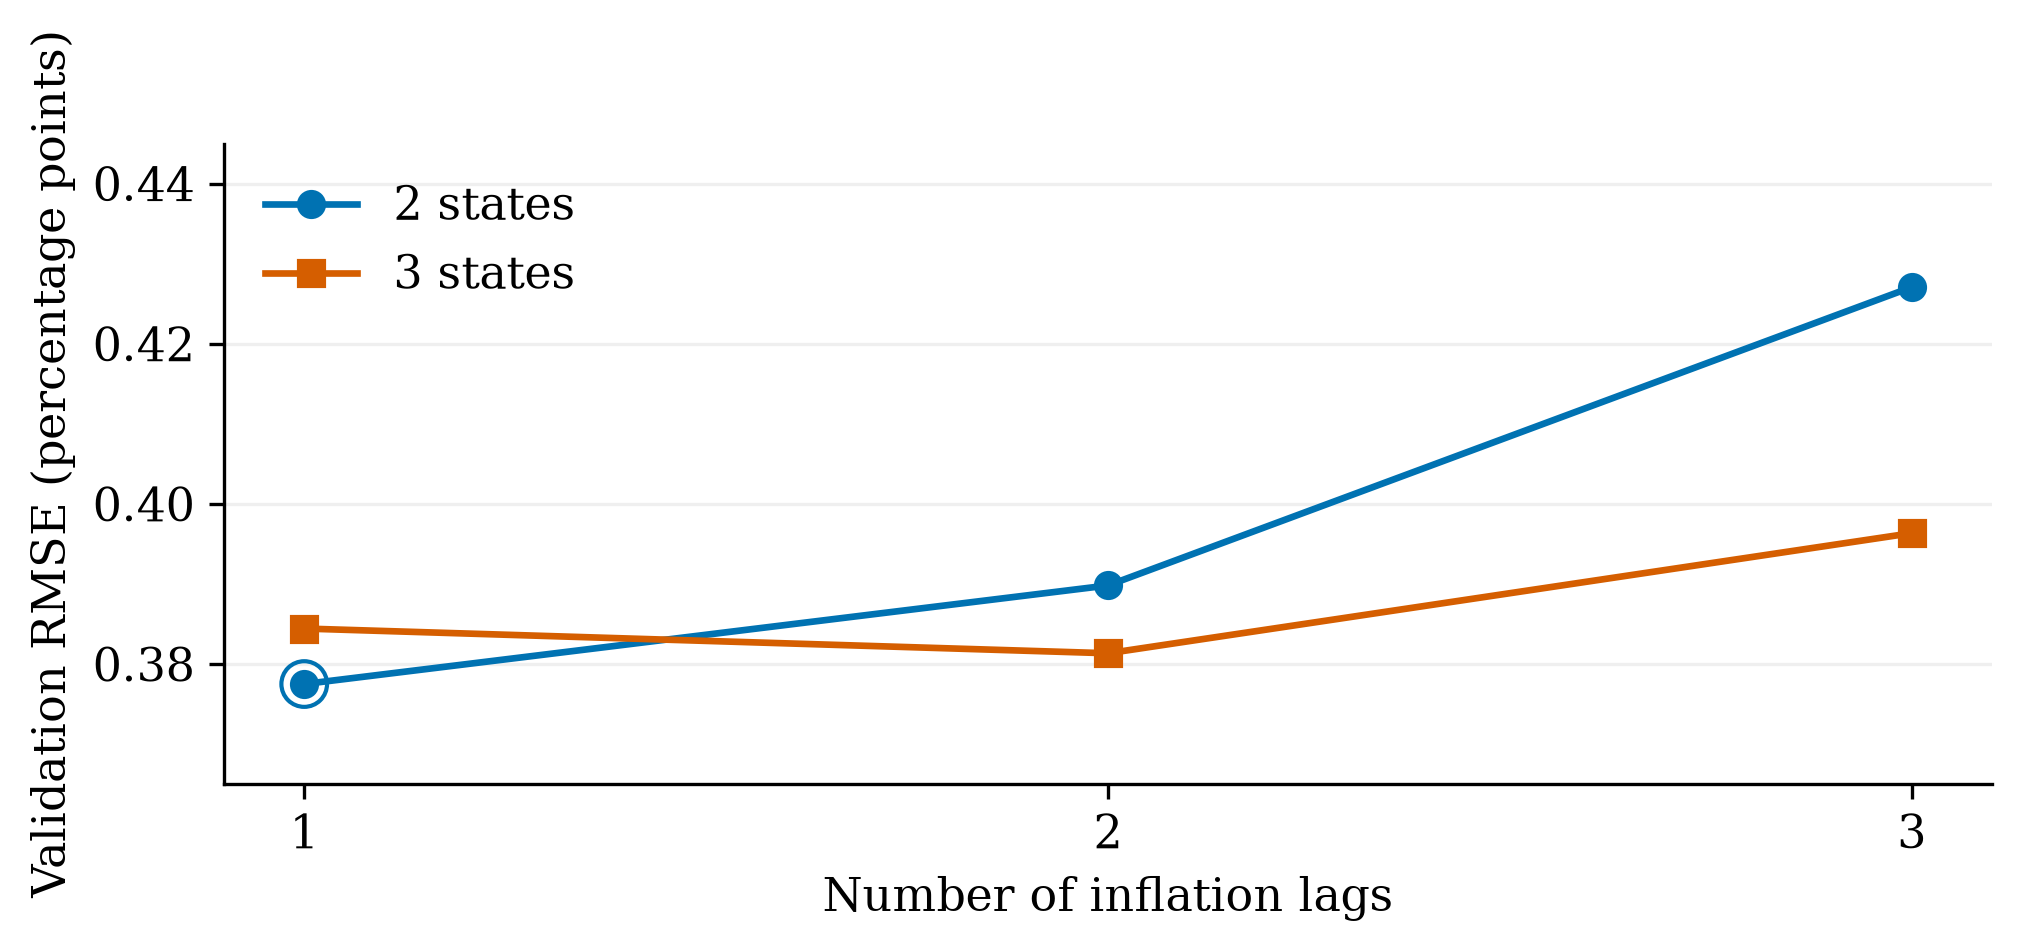

In [ ]:
selected_structure = results['structure_validation']['selected_structure']
state_lag_figure = plot_state_lag_selection(
    results['structure_validation'], ylim=(0.365, 0.445),
)
export_chapter4_figure(state_lag_figure, 'state_lag_selection.png', {
    'thesis_figure': '4.1',
    'source': ['structure_validation.validation_candidates', 'structure_validation.selected_structure'],
    'selection_period': results['structure_validation']['design']['selection_period'],
    'selected_model': selected_structure['model'],
    'selected_states': selected_structure['settings']['n_states'],
    'selected_inflation_lags': len(selected_structure['features']),
    'selected_validation_rmse': selected_structure['metrics']['rmse'],
})
display(state_lag_figure)
plt.close(state_lag_figure)


## Seasonally adjusted monthly inflation

fold,2007-2016 → 2017-2018,2007-2018 → 2019-2020,2007-2020 → 2021
model,,,
Seasonally adjusted AR(1),0.1732,0.1873,0.4014
Seasonally adjusted AR-HMM(1),0.1747,0.1885,0.3981
Seasonally adjusted AR-HMM(1) + all subject risks,0.1694,0.1894,0.3986


,model,rmse,mae,mean_error_actual_minus_forecast
2,Seasonally adjusted AR-HMM(1) + all subject risks,0.2400,0.1634,0.0288
1,Seasonally adjusted AR-HMM(1),0.2411,0.1610,0.0282
0,Seasonally adjusted AR(1),0.2414,0.1613,0.0260


,model,rmse,mae,mean_error_actual_minus_forecast
0,Seasonally adjusted AR(1),0.4331,0.3230,0.1596
2,Seasonally adjusted AR-HMM(1) + all subject risks,0.4396,0.3285,0.1724
1,Seasonally adjusted AR-HMM(1),0.4553,0.3493,0.1839


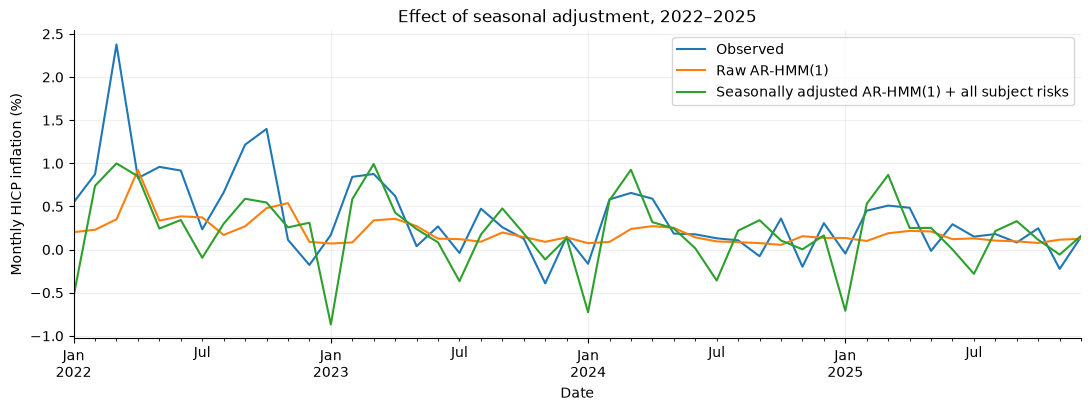

In [7]:
seasonal = results['seasonal_experiment']
rolling = seasonal['rolling_validation']
folds = pd.DataFrame([{'fold': fold['fold'], 'model': item['model'], **item['metrics']}
                      for fold in rolling['folds'] for item in fold['models']])
seasonal_validation = pd.DataFrame([{'model': item['model'], **item['metrics']}
                                    for item in rolling['combined_models']]).sort_values('rmse')
seasonal_test = pd.DataFrame([{'model': item['model'], **item['metrics']}
                              for item in seasonal['final_test']]).sort_values('rmse')
display(folds.pivot(index='model', columns='fold', values='rmse').round(4))
display(seasonal_validation.round(4))
display(seasonal_test.round(4))
raw = next(item for item in results['models'] if item['model'] == 'AR-HMM(1)')
adjusted = next(item for item in seasonal['final_test']
                if item['model'] == rolling['preferred_model'])
raw_forecast = pd.DataFrame(raw['forecasts']).assign(Date=lambda x: pd.to_datetime(x.Date)).set_index('Date')
adjusted_forecast = pd.DataFrame(adjusted['forecasts']).assign(Date=lambda x: pd.to_datetime(x.Date)).set_index('Date')
comparison = raw_forecast[['Actual']].rename(columns={'Actual': 'Observed'})
comparison['Raw AR-HMM(1)'] = raw_forecast.Forecast
comparison[adjusted['model']] = adjusted_forecast.Forecast
comparison.plot(figsize=(13, 4), title='Effect of seasonal adjustment, 2022–2025')
plt.ylabel('Monthly HICP inflation (%)')
plt.grid(alpha=.2)
plt.show()

### Chapter 4: European regime detection and predicted probabilities


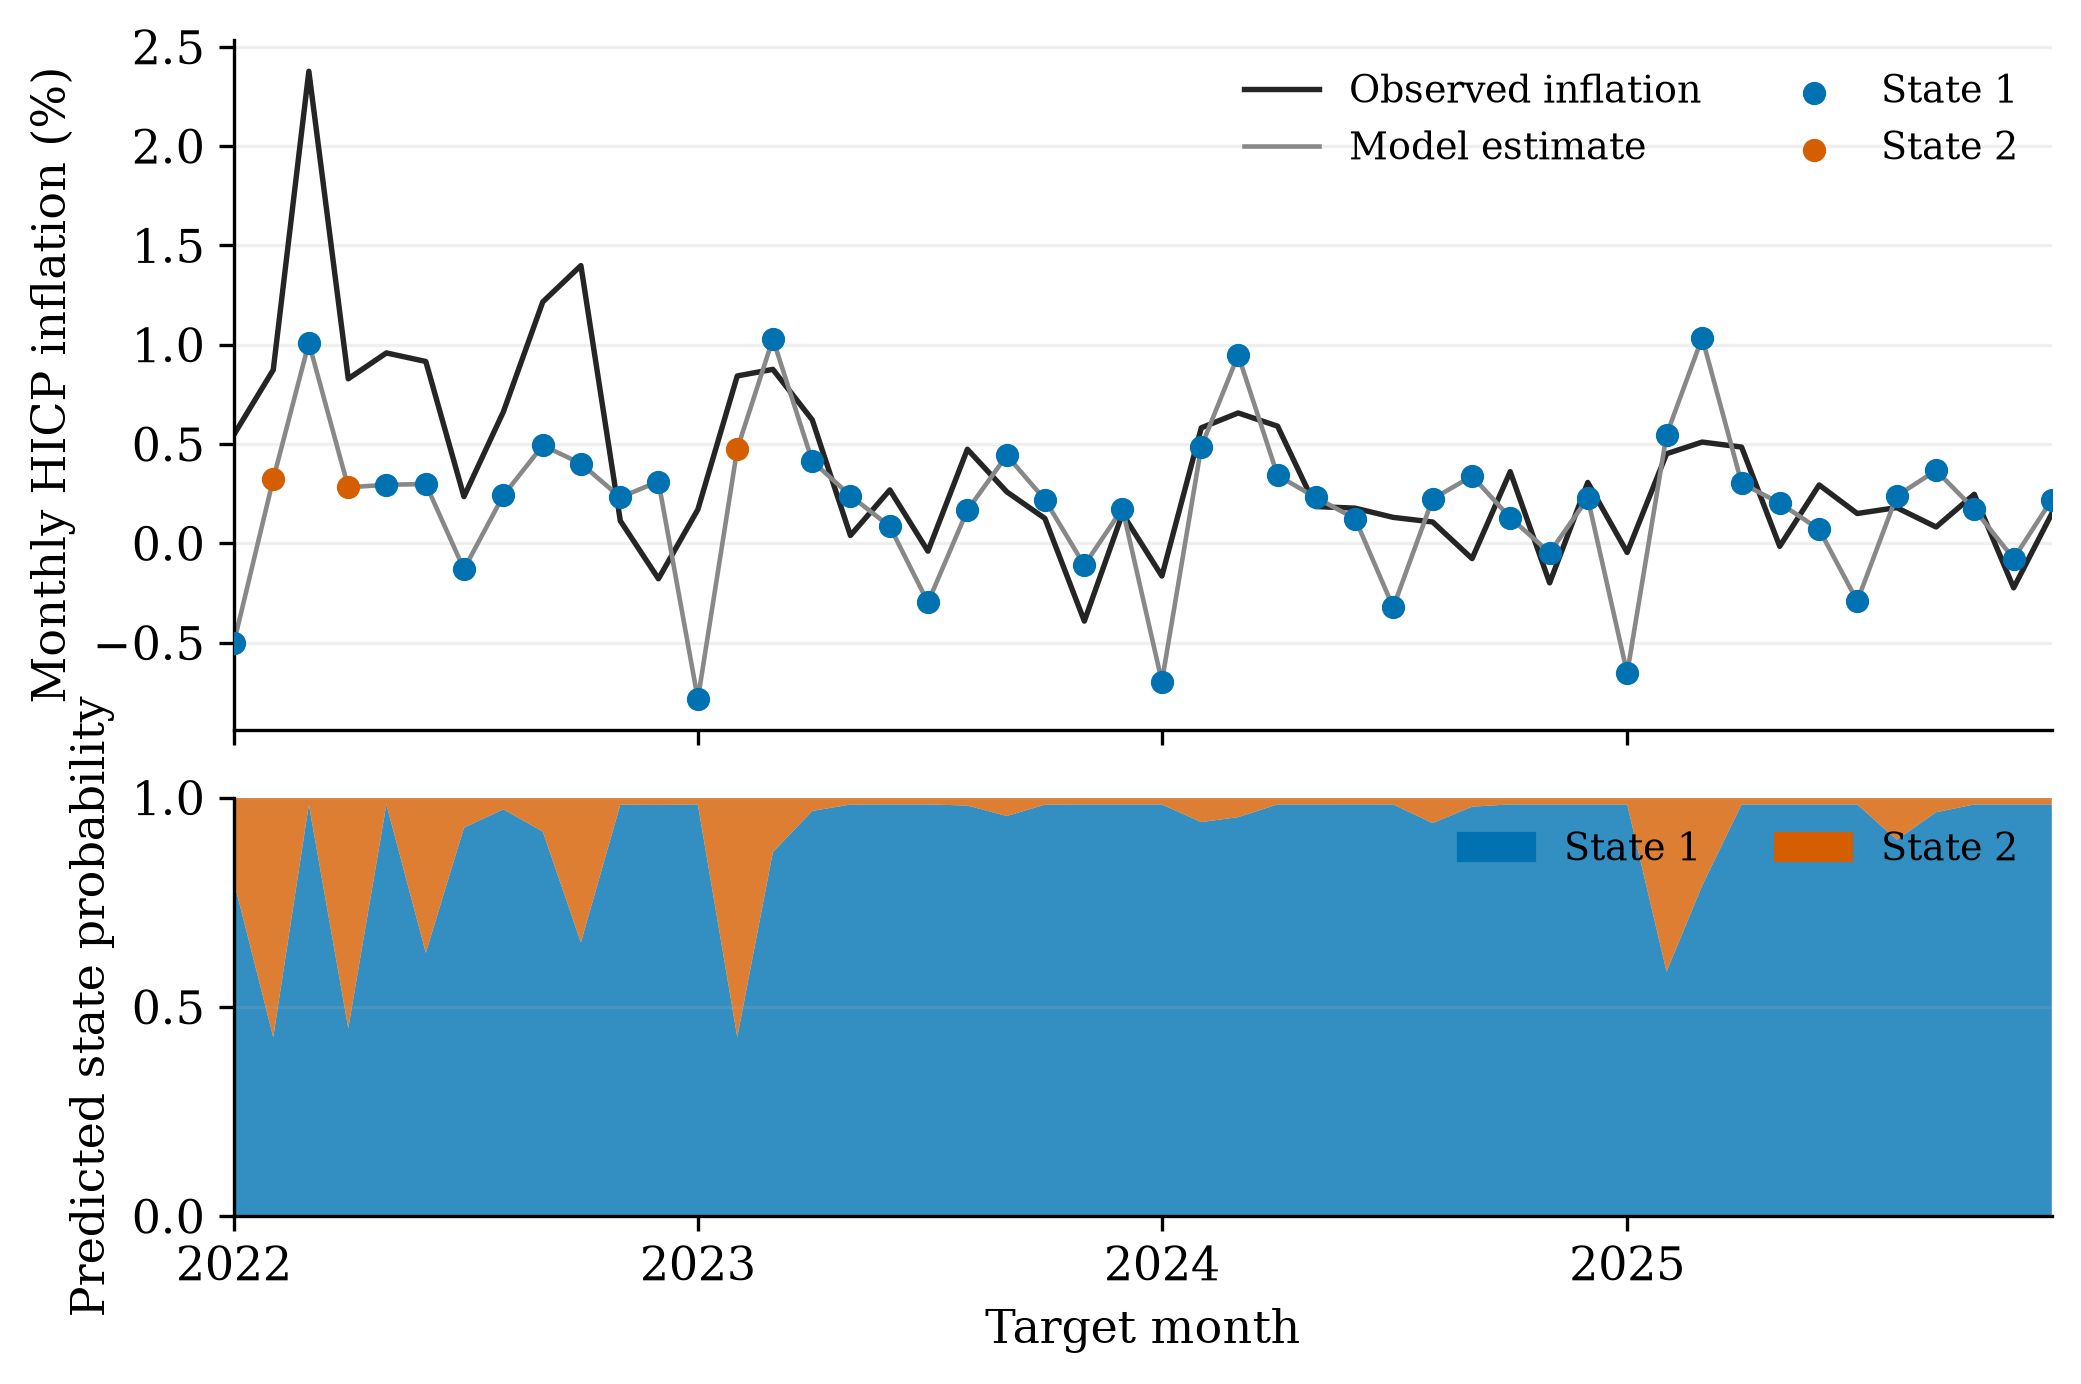

In [ ]:
regime_model = next(
    item for item in results['seasonal_experiment']['final_test']
    if item['model'] == 'Seasonally adjusted AR-HMM(1)'
)
regime_frame = pd.DataFrame(regime_model['forecasts'])
regime_figure = plot_european_regimes(regime_model)
export_chapter4_figure(regime_figure, 'eu_regime_detection.png', {
    'thesis_figure': '4.2',
    'source': 'seasonal_experiment.final_test',
    'model': regime_model['model'],
    'states': regime_model['parameters']['n_states'],
    'inflation_lags': len(regime_model['features']),
    'probability_timing': regime_model['parameters']['probability_timing'],
    'state_labels': regime_model['parameters']['regime_labels'],
    'predicted_state_counts': regime_frame.PredictedRegime.value_counts().to_dict(),
    'test_start': regime_frame.Date.min(),
    'test_end': regime_frame.Date.max(),
    'test_months': len(regime_frame),
})
display(regime_figure)
plt.close(regime_figure)


## Lagged macroeconomic indicators

,model,rmse,mae,mean_error_actual_minus_forecast
5,Seasonal AR-HMM(1) + energy block,0.2247,0.1498,0.0121
4,Seasonal AR-HMM(1) + energy PPI,0.2267,0.1519,0.0096
7,Seasonal AR-HMM(1) + all macro,0.2335,0.1596,0.0213
3,Seasonal AR-HMM(1) + energy HICP,0.2393,0.1623,0.0324
1,Seasonal AR-HMM(1) + unemployment,0.2415,0.1625,0.0232
0,Seasonal AR-HMM(1),0.2416,0.1610,0.0310
2,Seasonal AR-HMM(1) + industrial production,0.2434,0.1614,0.0315
6,Seasonal AR-HMM(1) + slow macro,0.2506,0.1699,0.0280


,model,RMSE 2022–2025,RMSE 2022,RMSE 2023–2025
1,Seasonal AR-HMM(1) + unemployment,0.4304,0.6789,0.3055
0,Seasonal AR-HMM(1),0.4331,0.6820,0.3083
2,Seasonal AR-HMM(1) + industrial production,0.4342,0.6891,0.3052
6,Seasonal AR-HMM(1) + slow macro,0.4356,0.6944,0.3037
7,Seasonal AR-HMM(1) + all macro,0.4509,0.6819,0.3406
5,Seasonal AR-HMM(1) + energy block,0.4538,0.7043,0.3304
4,Seasonal AR-HMM(1) + energy PPI,0.4594,0.7010,0.3430
3,Seasonal AR-HMM(1) + energy HICP,0.4674,0.7375,0.3317


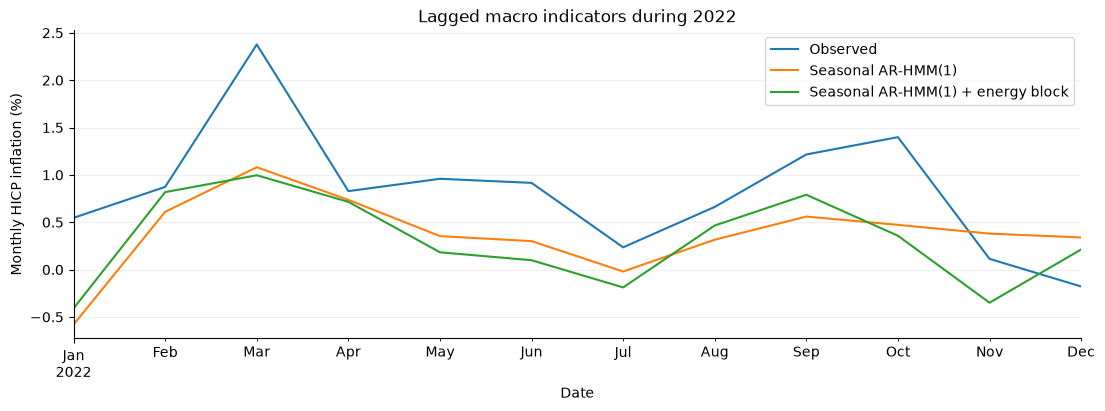

In [8]:
macro = results['macro_experiment']
macro_validation = pd.DataFrame([{'model': item['model'], **item['metrics']}
                                 for item in macro['rolling_validation']['combined_models']])
macro_test = pd.DataFrame([{'model': item['model'], 'RMSE 2022–2025': item['metrics']['rmse'],
                            'RMSE 2022': item['subperiod_metrics']['2022']['rmse'],
                            'RMSE 2023–2025': item['subperiod_metrics']['2023-2025']['rmse']}
                           for item in macro['final_test']])
display(macro_validation.sort_values('rmse').round(4))
display(macro_test.sort_values('RMSE 2022–2025').round(4))
baseline = next(item for item in macro['final_test'] if item['model'] == 'Seasonal AR-HMM(1)')
energy = next(item for item in macro['final_test'] if item['model'] == macro['preferred_model'])
baseline_2022 = pd.DataFrame(baseline['forecasts']).assign(Date=lambda x: pd.to_datetime(x.Date)).query("Date < '2023-01-01'").set_index('Date')
energy_2022 = pd.DataFrame(energy['forecasts']).assign(Date=lambda x: pd.to_datetime(x.Date)).query("Date < '2023-01-01'").set_index('Date')
plot_2022 = baseline_2022[['Actual']].rename(columns={'Actual': 'Observed'})
plot_2022['Seasonal AR-HMM(1)'] = baseline_2022.Forecast
plot_2022[energy['model']] = energy_2022.Forecast
plot_2022.plot(figsize=(13, 4), title='Lagged macro indicators during 2022')
plt.ylabel('Monthly HICP inflation (%)')
plt.grid(alpha=.2)
plt.show()

## Macroeconomic lag selection

In [9]:
macro_lags = results['macro_lag_experiment']
lag_grid = pd.DataFrame([{'indicator': item['indicator'], 'lag': item['lag'],
                           'validation_rmse': item['metrics']['rmse']}
                          for item in macro_lags['candidates']])
display(lag_grid.pivot(index='indicator', columns='lag', values='validation_rmse').round(4))
display(pd.Series(macro_lags['selected_lags'], name='Selected lag').to_frame())
lag_test = pd.DataFrame([{'model': item['model'], 'RMSE 2022–2025': item['metrics']['rmse'],
                          'RMSE 2022': item['subperiod_metrics']['2022']['rmse'],
                          'RMSE 2023–2025': item['subperiod_metrics']['2023-2025']['rmse']}
                         for item in macro_lags['final_test']])
display(lag_test.sort_values('RMSE 2022–2025').round(4))

lag,1,2,3,4,5,6
indicator,,,,,,
energy HICP,0.2342,0.2535,0.2462,0.2401,0.2434,0.2363
energy PPI,0.2267,0.2677,0.2399,0.2452,0.2359,0.2340
industrial production,0.2426,0.3296,0.2492,0.2427,0.2828,0.2426
unemployment,0.2412,0.2406,0.2365,0.2452,0.2476,0.2464


,Selected lag
unemployment,3
industrial production,1
energy HICP,1
energy PPI,1


,model,RMSE 2022–2025,RMSE 2022,RMSE 2023–2025
1,Seasonal AR-HMM(1) + unemployment lag 3,0.4279,0.6820,0.2985
0,Seasonal AR-HMM(1),0.4331,0.6820,0.3083
2,Seasonal AR-HMM(1) + industrial production lag 1,0.4429,0.6751,0.3311
4,Seasonal AR-HMM(1) + energy PPI lag 1,0.4594,0.7010,0.3430
5,Seasonal AR-HMM(1) + selected macro lags,0.4647,0.7113,0.3453
3,Seasonal AR-HMM(1) + energy HICP lag 1,0.4674,0.7375,0.3317


## Guardian sentiment nowcast

In [10]:
sentiment = results['sentiment_nowcast_experiment']
sentiment_validation = pd.DataFrame([{'model': item['model'], 'Validation RMSE': item['metrics']['rmse']}
                                     for item in sentiment['rolling_validation']['combined_models']])
sentiment_test = pd.DataFrame([{'model': item['model'], 'RMSE 2022–2025': item['metrics']['rmse'],
                                'RMSE 2022': item['subperiod_metrics']['2022']['rmse'],
                                'RMSE 2023–2025': item['subperiod_metrics']['2023-2025']['rmse']}
                               for item in sentiment['final_test']])
display(pd.Series({'Validation-selected model': sentiment['preferred_model']}))
display(sentiment_validation.sort_values('Validation RMSE').round(4))
display(sentiment_test.sort_values('RMSE 2022–2025').round(4))

Validation-selected model    Seasonal AR-HMM(1) + energy risk
dtype: str

,model,Validation RMSE
6,Seasonal AR-HMM(1) + energy risk,0.2395
1,Seasonal AR-HMM(1) + mean sentiment,0.2405
7,Seasonal AR-HMM(1) + supply-chain risk,0.2407
0,Seasonal AR-HMM(1) nowcast baseline,0.2408
4,Seasonal AR-HMM(1) + sentiment dispersion,0.2417
2,Seasonal AR-HMM(1) + median sentiment,0.2434
3,Seasonal AR-HMM(1) + negative share,0.2462
5,Seasonal AR-HMM(1) + geopolitical risk,0.2485
8,Seasonal AR-HMM(1) + all subject risks,0.2557


,model,RMSE 2022–2025,RMSE 2022,RMSE 2023–2025
8,Seasonal AR-HMM(1) + all subject risks,0.4156,0.6387,0.3072
7,Seasonal AR-HMM(1) + supply-chain risk,0.4263,0.6803,0.2967
0,Seasonal AR-HMM(1) nowcast baseline,0.4331,0.6820,0.3083
3,Seasonal AR-HMM(1) + negative share,0.4335,0.6910,0.3023
6,Seasonal AR-HMM(1) + energy risk,0.4337,0.6749,0.3145
2,Seasonal AR-HMM(1) + median sentiment,0.4347,0.6970,0.3000
1,Seasonal AR-HMM(1) + mean sentiment,0.4374,0.7037,0.3001
4,Seasonal AR-HMM(1) + sentiment dispersion,0.4383,0.7060,0.2999
5,Seasonal AR-HMM(1) + geopolitical risk,0.4477,0.7147,0.3115


## Final macro and sentiment comparison

Validation-selected model    Seasonal AR-HMM(1) + energy PPI lag 1
dtype: str

,model,Validation RMSE
1,Seasonal AR-HMM(1) + energy PPI lag 1,0.2267
2,Seasonal AR-HMM(1) + energy-risk sentiment,0.2395
0,Seasonal AR-HMM(1) baseline,0.2408
3,Seasonal AR-HMM(1) + macro and sentiment,0.2665


,model,RMSE 2022–2025,RMSE 2022,RMSE 2023–2025
0,Seasonal AR-HMM(1) baseline,0.4331,0.6820,0.3083
2,Seasonal AR-HMM(1) + energy-risk sentiment,0.4337,0.6749,0.3145
1,Seasonal AR-HMM(1) + energy PPI lag 1,0.4594,0.7010,0.3430
3,Seasonal AR-HMM(1) + macro and sentiment,0.4743,0.7428,0.3406


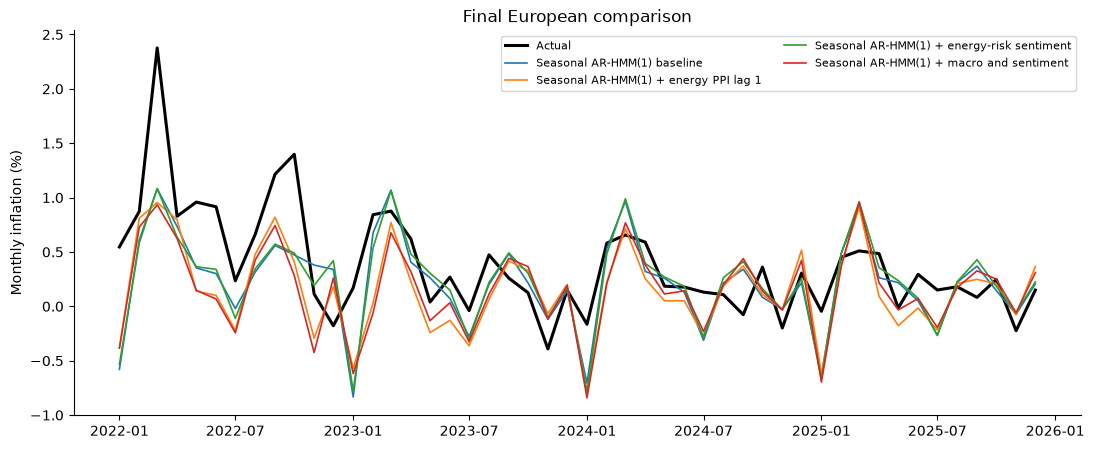

In [11]:
final_comparison = results['final_europe_comparison']
final_validation = pd.DataFrame([{'model': item['model'], 'Validation RMSE': item['metrics']['rmse']}
                                 for item in final_comparison['rolling_validation']['combined_models']])
final_test = pd.DataFrame([{'model': item['model'], 'RMSE 2022–2025': item['metrics']['rmse'],
                            'RMSE 2022': item['subperiod_metrics']['2022']['rmse'],
                            'RMSE 2023–2025': item['subperiod_metrics']['2023-2025']['rmse']}
                           for item in final_comparison['final_test']])
display(pd.Series({'Validation-selected model': final_comparison['preferred_model']}))
display(final_validation.sort_values('Validation RMSE').round(4))
display(final_test.sort_values('RMSE 2022–2025').round(4))
fig, ax = plt.subplots(figsize=(13, 5))
for item in final_comparison['final_test']:
    forecasts = pd.DataFrame(item['forecasts'])
    forecasts['Date'] = pd.to_datetime(forecasts['Date'])
    if item is final_comparison['final_test'][0]:
        ax.plot(forecasts.Date, forecasts.Actual, color='black', linewidth=2.2, label='Actual')
    ax.plot(forecasts.Date, forecasts.Forecast, linewidth=1.2, label=item['model'])
ax.set(title='Final European comparison', ylabel='Monthly inflation (%)', xlabel='')
ax.legend(fontsize=8, ncol=2)
plt.show()